# Visualize TotalSegmentator nnU-Net on TCIA

Run from the repository root with the same environment as `./eval_total_segmentator`.
This notebook uses the script's default paths, native nnU-Net v1 inference settings,
and TCIA label mapping: background=0, adipose=1 (SAT/VAT/IMAT), muscle=2.
Inference runs on the selected patient's entire raw CT volume; only the selected
held-out slice is visualized and scored. Set `fold` (0–4) and `idx` below.
`nnunet_fold` selects the model's training fold independently of the TCIA split.

In [1]:
import os
from pathlib import Path

# Configure the GPU before importing torch or nnU-Net.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "7")
os.environ["KERAS_BACKEND"] = "torch"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "1")

data_dir = Path("~/Documents/Datasets/TCIA/processed/").expanduser().resolve()
raw_dataset_dir = Path("~/Documents/Datasets/TCIA/raw/").expanduser().resolve()
model_path = Path(
    "models/.totalsegmentator/nnunet/results/nnUNet/2d/"
    "Task927_FatMuscle/nnUNetTrainerV2__nnUNetPlansv2.1"
).resolve()
fold = 0
idx = 8
nnunet_fold = "all"
checkpoint_name = "model_final_checkpoint"
num_workers = 1
label_map = [0, 1, 1, 1, 2]

## Load the held-out slice and locate its raw CT

/home/qhe2/Applications/miniconda3/envs/Comp2Comp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Patient: 0522c0017; raw slice: 75; held-out fold: 0
Image shape: (512, 512, 3); mask shape: (512, 512)


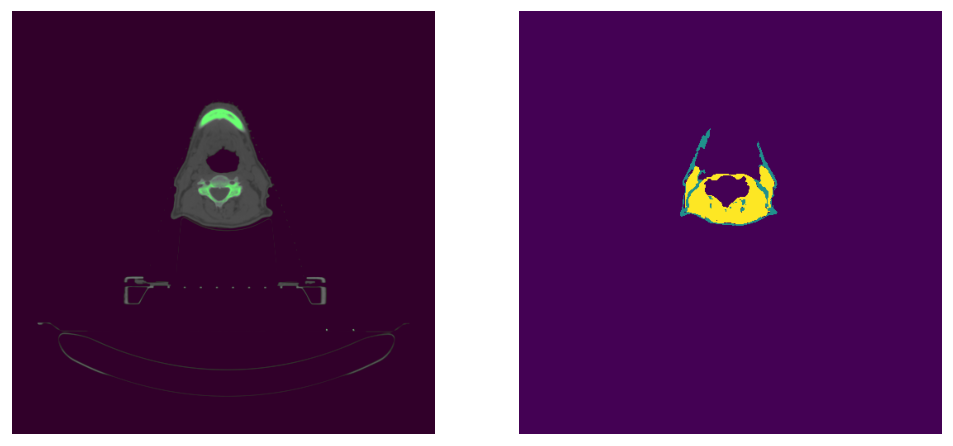

In [2]:
import numpy as np
import torch
from torch.nn import functional as F
import data
from eval import (
    resolve_nnunet_checkpoint, nrrd_to_nifti,
    update_confusion, confusion_metrics,
)

_, dataset = data.load(data_dir, preprocessed=True, fold_idx=fold)
if not 0 <= idx < len(dataset):
    raise IndexError(f"idx={idx} is outside the held-out split of {len(dataset)} slices")
x, y = dataset[idx]
truth = y.detach().cpu().numpy()
sample = dataset.dataset.slices[dataset.indices[idx]]
source_indices = np.load(
    sample.patient_dir / data.ProcessedTCIA.SLICE_INDICES_FILENAME,
    allow_pickle=False,
)
slice_index = int(source_indices[sample.index])
patient_dir = raw_dataset_dir / sample.patient_dir.name
print(f"Patient: {patient_dir.name}; raw slice: {slice_index}; held-out fold: {fold}")
print(f"Image shape: {tuple(x.shape)}; mask shape: {truth.shape}")

from io import BytesIO
from IPython.display import Image, display


def display_figure(fig):
    # Emit an image/png output even when the kernel uses the Agg backend
    # or has no Matplotlib inline formatter registered.
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
from matplotlib import pyplot as plt

# Match eval.ipynb: transpose spatial axes and normalize the full RGB image.
x_np = x.permute(1, 0, 2).detach().cpu().numpy()
x_np = (x_np - x_np.min()) / (x_np.max() - x_np.min())
y_np = y.permute(1, 0).detach().cpu().numpy()

fig = plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(x_np, cmap="gray" if x_np.ndim == 2 else None)
# plt.title("image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(y_np)
# plt.title("label")
plt.axis("off")

display_figure(fig)
plt.close(fig)


## Run native nnU-Net inference

Uses the same checkpoint resolver, NRRD conversion, inference options, and nearest-neighbor alignment as `eval.py`. Temporary NIfTI files are removed after prediction.

In [3]:
import tempfile
import nrrd
from nibabel.loadsave import load, save
from nibabel.processing import resample_from_to
from nnunet.inference import predict

trainer_dir, model_folds, resolved_checkpoint = resolve_nnunet_checkpoint(
    model_path, nnunet_fold, checkpoint_name
)
mapping = np.asarray(label_map)
if (mapping.ndim != 1 or not len(mapping)
        or not np.isin(mapping, (0, 1, 2)).all() or mapping[0] != 0):
    raise ValueError("label_map must map class 0 to 0 and all classes to 0, 1, or 2")

image, header = nrrd.read(str(patient_dir / data.TCIA.IMAGE_FILENAME), index_order="F")
if not 0 <= slice_index < image.shape[2]:
    raise ValueError(f"Source slice {slice_index} is outside CT shape {image.shape}")
source = nrrd_to_nifti(image, header)
with tempfile.TemporaryDirectory(prefix="visualize_nnunet_") as tmp:
    input_path = str(Path(tmp) / "ct.nii.gz")
    output_path = str(Path(tmp) / "seg.nii.gz")
    save(source, input_path)
    predict.predict_cases(
        model=str(trainer_dir), list_of_lists=[[input_path]],
        output_filenames=[output_path], folds=model_folds, save_npz=False,
        num_threads_preprocessing=max(1, num_workers),
        num_threads_nifti_save=max(1, num_workers),
        segs_from_prev_stage=None, do_tta=False, mixed_precision=True,
        overwrite_existing=False, all_in_gpu=False, step_size=0.5,
        checkpoint_name=resolved_checkpoint,
    )
    result = resample_from_to(load(output_path), source, order=0, mode="nearest")
    labels = np.asarray(result.dataobj)
    if not np.isin(labels, np.arange(len(mapping))).all():
        raise ValueError("nnU-Net predicted a class absent from label_map")
    prediction = mapping[labels[:, :, slice_index].astype(np.int64)]

if prediction.shape != truth.shape:
    prediction = F.interpolate(
        torch.from_numpy(prediction.astype(np.float32))[None, None],
        size=truth.shape, mode="nearest",
    )[0, 0].numpy().astype(np.int64)

counts = np.zeros((3, 3), dtype=np.int64)
update_confusion(counts, truth, prediction)
metrics = confusion_metrics(counts)
print("Selected-slice metrics (not whole-fold evaluation):")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")



Please cite the following paper when using nnUNet:

Isensee, F., Jaeger, P.F., Kohl, S.A.A. et al. "nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation." Nat Methods (2020). https://doi.org/10.1038/s41592-020-01008-z


If you have questions or suggestions, feel free to open an issue at https://github.com/MIC-DKFZ/nnUNet

nnUNet_raw_data_base is not defined and nnU-Net can only be used on data for which preprocessed files are already present on your system. nnU-Net cannot be used for experiment planning and preprocessing like this. If this is not intended, please read documentation/setting_up_paths.md for information on how to set this up properly.
nnUNet_preprocessed is not defined and nnU-Net can not be used for preprocessing or training. If this is not intended, please read documentation/setting_up_paths.md for information on how to set this up.
RESULTS_FOLDER is not defined and nnU-Net cannot be used for training or inference. If this is not in

/home/qhe2/Applications/miniconda3/envs/Comp2Comp/lib/python3.11/site-packages/nnunet/training/model_restore.py:147: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  all_params

preprocessing /tmp/visualize_nnunet_69a0o26l/seg.nii.gz
using preprocessor PreprocessorFor2D
before crop: (1, 156, 512, 512) after crop: (1, 156, 512, 512) spacing: [2.5        0.98000002 0.98000002] 

separate z, order in z is 0 order inplane is 3
separate z, order in z is 0 order inplane is 1
before: {'spacing': array([2.5       , 0.98000002, 0.98000002]), 'spacing_transposed': array([2.5       , 0.98000002, 0.98000002]), 'data.shape (data is transposed)': (1, 156, 512, 512)} 
after:  {'spacing': array([2.5       , 0.80859399, 0.80859399]), 'data.shape (data is resampled)': (1, 156, 621, 621)} 

normalization...
normalization done
(1, 156, 621, 621)
This worker has ended successfully, no errors to report
predicting /tmp/visualize_nnunet_69a0o26l/seg.nii.gz
debug: mirroring False mirror_axes (0, 1)


/home/qhe2/Applications/miniconda3/envs/Comp2Comp/lib/python3.11/site-packages/nnunet/training/network_training/network_trainer.py:404: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.amp_grad_scaler = GradScaler()
/home/qhe2/Applications/miniconda3/envs/Comp2Comp/lib/python3.11/site-packages/nnunet/network_architecture/neural_network.py:141: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with context():


inference done. Now waiting for the segmentation export to finish...
force_separate_z: None interpolation order: 1
separate z: True lowres axis [0]
separate z, order in z is 0 order inplane is 1
WARNING! Cannot run postprocessing because the postprocessing file is missing. Make sure to run consolidate_folds in the output folder of the model first!
The folder you need to run this in is /home/qhe2/Developer/comp2comp/models/.totalsegmentator/nnunet/results/nnUNet/2d/Task927_FatMuscle/nnUNetTrainerV2__nnUNetPlansv2.1
Selected-slice metrics (not whole-fold evaluation):
accuracy: 0.9848
dice: 0.6028
dice_background: 0.9929
dice_adipose: 0.2357
dice_muscle: 0.5797


## Predict

Display the mapped prediction with the same orientation, default colormap, and figure size as `eval.ipynb`.


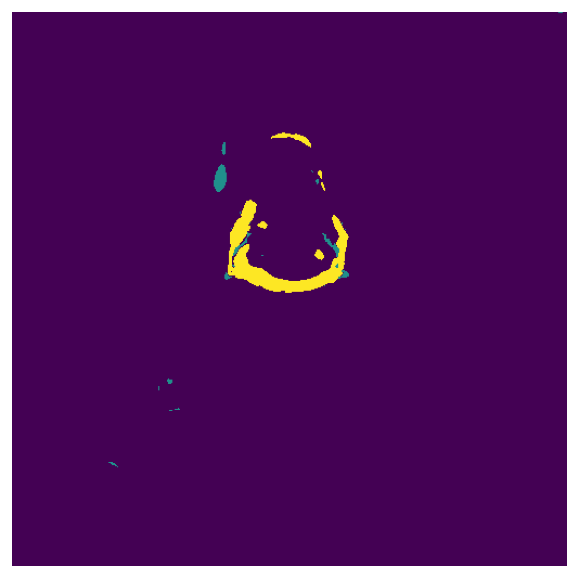

In [4]:
pred_np = prediction.T

fig = plt.figure(figsize=(6, 6))
plt.imshow(pred_np)
# plt.title("pred")
plt.axis("off")
display_figure(fig)
plt.close(fig)
